In [11]:
import sys
import pystac_client
import planetary_computer
import matplotlib.pyplot as plt

import numpy as np
import xarray as xr 
from scipy.ndimage import uniform_filter


import datacube
import odc.stac
from odc.geo.geom import BoundingBox

sys.path.insert(1, "../Tools/")
from dea_tools.datahandling import load_ard
from dea_tools.plotting import display_map

In [2]:
x = (152.958994, 153.019925)
y = (-27.490764, -27.522462)
time = ("2022-02", "2022-05")

In [3]:
display_map(x=x, y=y)

*Load data from Planetary Computer*

In [4]:
# Open a client pointing to the Microsoft Planetary Computer data catalogue
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

In [5]:
# Convert data-cube style queries into something readable by `pystac_client`
bbox = BoundingBox.from_xy(x, y)
time_range = "/".join(time)

# Search for STAC items from "sentinel-1-rtc" product
search = catalog.search(
    collections="sentinel-1-rtc",
    bbox=bbox,
    datetime=time_range,
)

# Check how many items were returned
items = search.item_collection()
print(f"Found {len(items)} STAC items")

Found 8 STAC items


In [7]:
# Load ESA WorldCover data with odc-stac
rtc = odc.stac.load(
    items,
    bbox=bbox,
    bands=["vv", "vh"],
    crs="EPSG:3577",
    resolution=30,
)

In [8]:
rtc

<xarray.Dataset> Size: 2MB
Dimensions:      (y: 150, x: 216, time: 8)
Coordinates:
  * y            (y) float64 1kB -3.149e+06 -3.149e+06 ... -3.154e+06 -3.154e+06
  * x            (x) float64 2kB 2.036e+06 2.036e+06 ... 2.042e+06 2.043e+06
    spatial_ref  int32 4B 3577
  * time         (time) datetime64[ns] 64B 2022-02-11T19:14:07.931034 ... 202...
Data variables:
    vv           (time, y, x) float32 1MB 16.11 0.1416 0.3512 ... 0.09461 0.2317
    vh           (time, y, x) float32 1MB 0.08596 0.05772 ... 0.02582 0.01913

In [9]:
def dB_scale(data): 
    '''Scales a xarray.DataArray with linear DN to a dB scale.'''
    # Explicitly set negative data to nan to avoid log of negative number
    negative_free_data = data.where(data >= 0, np.nan)
    return 10 * np.log10(negative_free_data)

# Visualise RTC samples

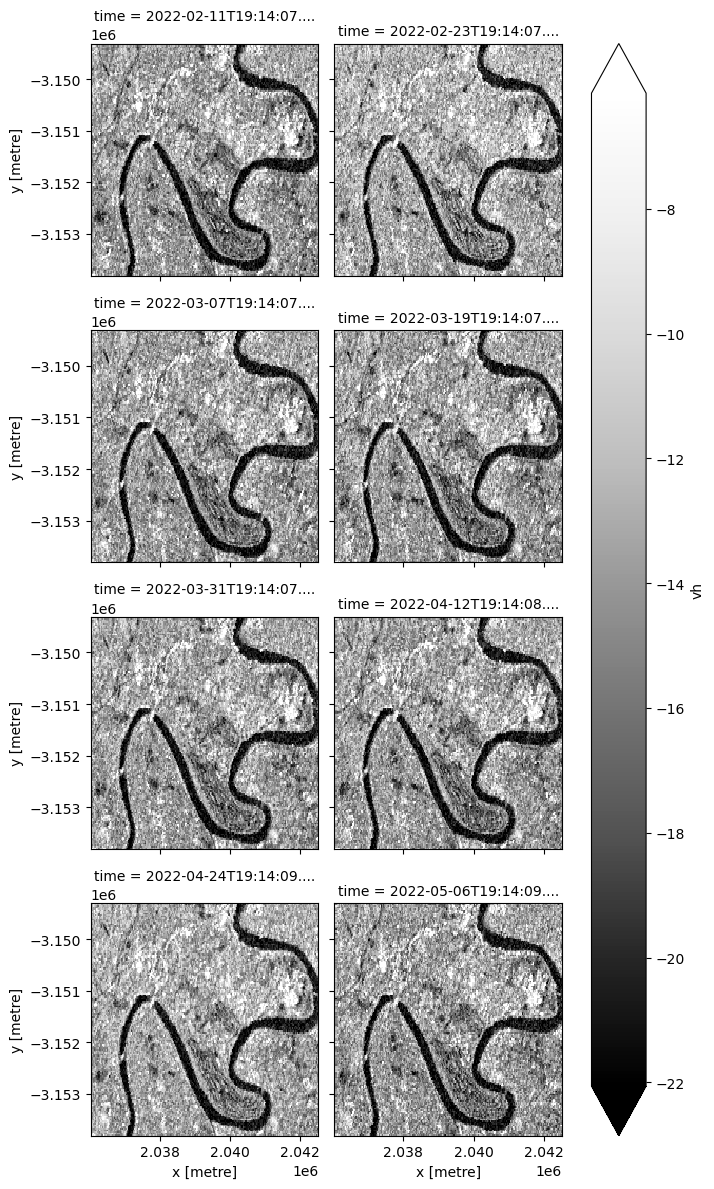

In [17]:
# Scale to plot data in decibels
rtc_db = {"vh": dB_scale(rtc.vh), "vv": dB_scale(rtc.vv)}

# Plot all VH observations for the year
rtc_db["vh"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()

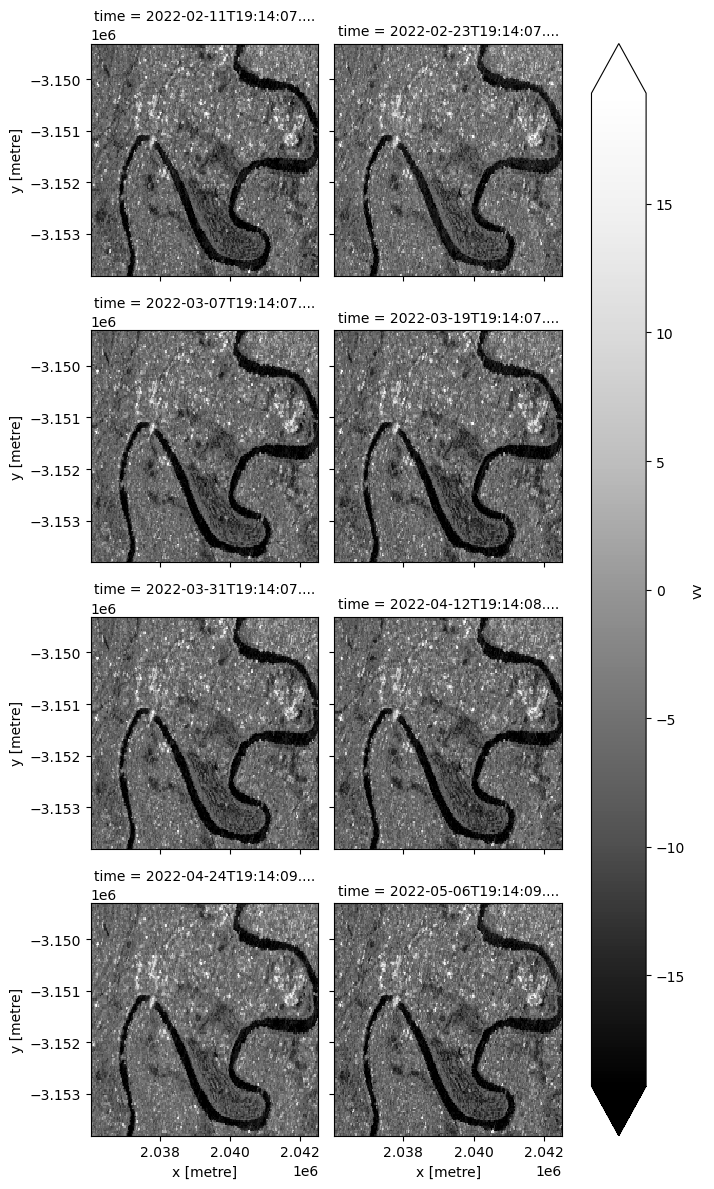

In [18]:
# Scale to plot data in decibels
# Plot all VH observations for the year
rtc_db["vv"].plot(cmap="Greys_r", robust=True, col="time", col_wrap=2)
plt.show()